# Result plots

Figures and tables for the two comparisons
- **Verification:** 2017–2019 against Welch et al. (2022)
- **Period comparison:** 2023–2025 against 2017–2019

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import xgboost as xgb
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, LogNorm, SymLogNorm
from matplotlib.ticker import FuncFormatter

from config import PERIODS
from gap_processing import gap_hours_raster

RUNS = {
    "2017–2019": "model_results/2017_2019",
    "2023–2025": "model_results/2023_2025",
}
P1, P2, PAPER = "2017–2019", "2023–2025", "Welch et al."
runs = {k: v for k, v in RUNS.items() if os.path.isdir(v)}
print("runs found:", list(runs))

OUT = "figures"
os.makedirs(OUT, exist_ok=True)

MODELS = {"full": "Full", "DRIFTING_LONGLINES": "Drifting longline", "SQUID_JIGGER": "Squid jigger",
          "TUNA_PURSE_SEINES": "Tuna purse seine", "TRAWLERS": "Trawler"}
DRIVERS = {"loitering_hours": "Loitering", "dist2coast": "Shore", "dist_mpa": "MPA", "dist_piracy": "Pirates",
           "sst": "SST", "sst_var": "SST SD", "chl": "Chl", "eke": "EKE"}
GEAR = {"DRIFTING_LONGLINES": "Drifting longline", "SQUID_JIGGER": "Squid jigger",
        "TUNA_PURSE_SEINES": "Tuna purse seine", "TRAWLERS": "Trawler"}

# Welch et al. (2022): relative importance, explained deviance, AUC, TSS
PAPER_IMPORTANCE = {
    "full": dict(loitering_hours=48.6, dist2coast=12.4, dist_mpa=2.0, dist_piracy=0.5, sst=9.8, sst_var=13.3, chl=10.3, eke=2.9),
    "DRIFTING_LONGLINES": dict(loitering_hours=5.4, dist2coast=34.0, dist_mpa=2.2, dist_piracy=2.9, sst=17.7, sst_var=18.1, chl=14.2, eke=7.5),
    "SQUID_JIGGER": dict(loitering_hours=37.3, dist2coast=7.5, dist_mpa=1.1, dist_piracy=2.3, sst=27.5, sst_var=14.9, chl=6.8, eke=3.3),
    "TUNA_PURSE_SEINES": dict(loitering_hours=2.1, dist2coast=9.5, dist_mpa=5.6, dist_piracy=21.9, sst=22.5, sst_var=10.8, chl=19.7, eke=5.9),
    "TRAWLERS": dict(loitering_hours=4.0, dist2coast=7.2, dist_mpa=4.0, dist_piracy=4.6, sst=11.7, sst_var=12.6, chl=49.2, eke=5.1),
}
PAPER_METRICS = {"full": (26.21, 0.81, 0.48), "DRIFTING_LONGLINES": (12.17, 0.73, 0.33), "SQUID_JIGGER": (47.08, 0.91, 0.67),
                 "TUNA_PURSE_SEINES": (16.53, 0.76, 0.40), "TRAWLERS": (61.42, 0.96, 0.79)}
PAPER_PRESENCES = {"full": 28874, "DRIFTING_LONGLINES": 15233, "SQUID_JIGGER": 3628, "TUNA_PURSE_SEINES": 6642, "TRAWLERS": 2342}

# colors
COL = {PAPER: "#898781", P1: "#6da7ec", P2: "#184f95"}
INK2, GRID, LAND, SURFACE = "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#3987e5", "#f0efec", "#e34948"])
W_FULL, W_COL = 17 / 2.54, 8.2 / 2.54  # inches
plt.rcParams.update({
    "font.size": 7, "axes.titlesize": 7.5, "axes.labelsize": 7, "xtick.labelsize": 6.5, "ytick.labelsize": 6.5,
    "legend.fontsize": 6.5, "axes.edgecolor": LAND, "axes.linewidth": 0.6, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "savefig.dpi": 300, "pdf.fonttype": 42,
})


def save(fig, name):
    fig.savefig(f"{OUT}/{name}.pdf", bbox_inches="tight")
    fig.savefig(f"{OUT}/{name}.png", bbox_inches="tight")


def importance(run, model):
    """Relative importance in % for one run and model."""
    s = pd.Series(json.load(open(f"{runs[run]}/importance_{model}.json")))
    return 100 * s / s.sum()


def metrics(run, model):
    return json.load(open(f"{runs[run]}/metrics_{model}.json"))

runs found: ['2017–2019', '2023–2025']


## Driver importance (paper Fig. 3)

,,Loitering,Shore,MPA,Pirates,SST,SST SD,Chl,EKE
model,run,,,,,,,,
Full,Welch et al.,48.6,12.4,2.0,0.5,9.8,13.3,10.3,2.9
Drifting longline,Welch et al.,5.4,34.0,2.2,2.9,17.7,18.1,14.2,7.5
Squid jigger,Welch et al.,37.3,7.5,1.1,2.3,27.5,14.9,6.8,3.3
Tuna purse seine,Welch et al.,2.1,9.5,5.6,21.9,22.5,10.8,19.7,5.9
Trawler,Welch et al.,4.0,7.2,4.0,4.6,11.7,12.6,49.2,5.1
Full,2017–2019 (paper events),47.0,14.9,3.4,1.7,11.1,8.7,9.9,3.5
Drifting longline,2017–2019 (paper events),6.3,36.7,2.5,3.0,20.6,14.4,9.0,7.5
Squid jigger,2017–2019 (paper events),42.9,8.0,5.2,3.4,15.8,11.8,8.3,4.5
Tuna purse seine,2017–2019 (paper events),2.0,17.7,6.9,21.8,19.5,10.7,15.2,6.1


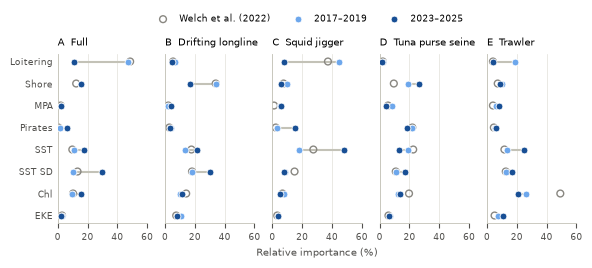

In [5]:
rows = [{"model": MODELS[m], "run": PAPER, **PAPER_IMPORTANCE[m]} for m in MODELS]
rows += [{"model": MODELS[m], "run": r, **importance(r, m)} for r in runs for m in MODELS]
imp = pd.DataFrame(rows).set_index(["model", "run"])[list(DRIVERS)].rename(columns=DRIVERS).round(1)
imp.to_csv(f"{OUT}/importance_table.csv")

xmax = 10 * np.ceil((imp.values.max() + 2) / 10)  # +2 so markers near a round number aren't cut off
y = np.arange(len(DRIVERS))[::-1]  # first driver on top
fig, axes = plt.subplots(1, len(MODELS), figsize=(W_FULL, 2.2), sharey=True)
for ax, (m, title), letter in zip(axes, MODELS.items(), "ABCDE"):
    ax.grid(axis="x", color=GRID, lw=0.5)
    ax.set_axisbelow(True)
    if P1 in runs and P2 in runs:
        ax.hlines(y, importance(P1, m)[list(DRIVERS)], importance(P2, m)[list(DRIVERS)], color=LAND, lw=1.5, zorder=1)
    ax.scatter(pd.Series(PAPER_IMPORTANCE[m])[list(DRIVERS)], y, s=24, facecolor="none", edgecolor=COL[PAPER],
               lw=1, zorder=2, label="Welch et al. (2022)")
    for r in (P1, P2):
        if r in runs:
            ax.scatter(importance(r, m)[list(DRIVERS)], y, s=24, color=COL[r], edgecolor="white", lw=0.6, zorder=3, label=r)
    ax.set_title(f"{letter}  {title}", loc="left")
    ax.set_xlim(0, xmax)
    ax.tick_params(axis="y", length=0)
axes[0].set_yticks(y, list(DRIVERS.values()))
axes[len(MODELS) // 2].set_xlabel("Relative importance (%)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.1))
save(fig, "fig_importance")
imp

## Model performance (paper Table S6)

In [2]:
cols = [PAPER] + list(runs)
perf = pd.DataFrame(
    {MODELS[m]: list(PAPER_METRICS[m]) + [metrics(r, m)[k] for r in runs for k in ("explained_deviance", "auc_mean", "tss_mean")]
     for m in MODELS},
    index=pd.MultiIndex.from_product([cols, ["Dev. (%)", "AUC", "TSS"]])).T

lines = [r"\begin{table*}[t]", r"\centering",
         r"\caption{Model performance: explained deviance of the final models (\%), and mean AUC and TSS of 50 random 75/25 "
         r"train--test splits. Values for Welch et al. are from their Table S6.}",
         r"\label{tab:performance}", r"\small", r"\begin{tabular}{l" + "ccc" * len(cols) + "}", r"\hline",
         " & " + " & ".join(rf"\multicolumn{{3}}{{c}}{{{c}}}" for c in cols) + r" \\",
         " & " + " & ".join(["Dev.", "AUC", "TSS"] * len(cols)) + r" \\", r"\hline"]
lines += [f"{name} & " + " & ".join(f"{v:.1f}" if j % 3 == 0 else f"{v:.2f}" for j, v in enumerate(row)) + r" \\"
          for name, row in perf.iterrows()]
lines += [r"\hline", r"\end{tabular}", r"\end{table*}"]
open(f"{OUT}/table_performance.tex", "w").write("\n".join(lines))
perf.round(2)

Welch et al.             2017–2019             2023–2025  \
                      Dev. (%)   AUC   TSS  Dev. (%)   AUC   TSS  Dev. (%)   
Full                     26.21  0.81  0.48     26.19  0.73  0.35     20.56   
Drifting longline        12.17  0.73  0.33     11.04  0.68  0.26     15.63   
Squid jigger             47.08  0.91  0.67     56.84  0.88  0.62     58.40   
Tuna purse seine         16.53  0.76  0.40     17.49  0.72  0.35     16.79   
Trawler                  61.42  0.96  0.79     61.98  0.86  0.60     56.04   

                               
                    AUC   TSS  
Full               0.74  0.36  
Drifting longline  0.72  0.34  
Squid jigger       0.88  0.57  
Tuna purse seine   0.71  0.32  
Trawler            0.85  0.56

## Number of events, time lost and presences per gear type (paper Table S5)

/tmp/ipykernel_55473/315739956.py:6: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  df = df.assign(hours=(end - start).dt.total_seconds() / 3600)[(start >= t0) & (end < t1 + pd.Timedelta(days=1))]
/tmp/ipykernel_55473/315739956.py:6: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  df = df.assign(hours=(end - start).dt.total_seconds() / 3600)[(start >= t0) & (end < t1 + pd.Timedelta(days=1))]


events                        hours (M)            \
                  Welch et al. 2017–2019 2023–2025 Welch et al. 2017–2019   
gear                                                                        
Drifting longline        18641     16223     24372         0.81      0.71   
Squid jigger             16021     16597     10094         0.62      0.65   
Tuna purse seine          8620      8459      8459         0.53      0.51   
Trawler                   7913      8217      5315         0.40      0.41   
Other                     4173     14441     21863         0.21      0.64   
All                      55368     63937     70103         2.57      2.93   

                               presences                      
                  2023–2025 Welch et al. 2017–2019 2023–2025  
gear                                                          
Drifting longline      1.21      15233.0   12852.0   16395.0  
Squid jigger           0.35       3628.0    3624.0    3176.0  
Tuna purse seine       0.56       6642.0    5929.0    5342.0  
Trawler                0.25       2342.0    1254.0    1054.0  
Other                  1.00          NaN       NaN       NaN  
All                    3.38      28874.0   25568.0   27830.0

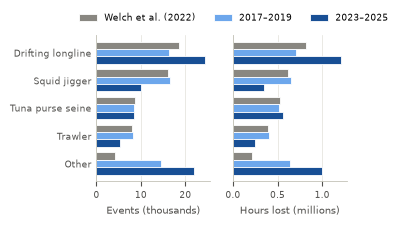

In [7]:
def load_gaps(period):
    """API gaps of one period: start and end inside the period, duration in hours."""
    df = pd.read_csv(f"data/processed/gaps_{period}_filtered.csv")
    start, end = (pd.to_datetime(df[c], utc=True) for c in ("start", "end"))
    t0, t1 = (pd.Timestamp(d, tz="UTC") for d in PERIODS[period])
    df = df.assign(hours=(end - start).dt.total_seconds() / 3600)[(start >= t0) & (end < t1 + pd.Timedelta(days=1))]
    return df.drop_duplicates("id")


ev = pd.read_csv("disabling_events.csv")
GAPS = {PAPER: pd.DataFrame({
    "gap": [{"off_position": {"lat": a, "lon": b}, "on_position": {"lat": c, "lon": d}, "duration_hours": h}
            for a, b, c, d, h in ev[["gap_start_lat", "gap_start_lon", "gap_end_lat", "gap_end_lon", "gap_hours"]].values],
    "gear_type": ev["vessel_class"], "hours": ev["gap_hours"]})}
for label, period in [(P1, "2017_2019"), (P2, "2023_2025")]:
    if os.path.exists(f"data/processed/gaps_{period}_filtered.csv"):
        GAPS[label] = load_gaps(period)

MODEL_OF = {**{v: k for k, v in GEAR.items()}, "All": "full"}  # gear row -> model whose presences it lists


def presences(label, name):
    m = MODEL_OF.get(name)
    if m is None or (label != PAPER and label not in runs):
        return np.nan
    return PAPER_PRESENCES[m] if label == PAPER else metrics(label, m)["n_presence"]


rows = []
for label, g in GAPS.items():
    gear = g["gear_type"].astype(str).str.upper().map(GEAR).fillna("Other")
    short = g["hours"] < 336  # 14 days, as for the maps
    for name in list(GEAR.values()) + ["Other", "All"]:
        sel = gear == name if name != "All" else gear.notna()
        rows.append({"gear": name, "data": label, "events": int(sel.sum()),
                     "hours (M)": g.loc[sel & short, "hours"].sum() / 1e6, "presences": presences(label, name)})
scale = (pd.DataFrame(rows).pivot(index="gear", columns="data").reindex(list(GEAR.values()) + ["Other", "All"])
         .reindex(columns=pd.MultiIndex.from_product([["events", "hours (M)", "presences"], list(GAPS)])))
scale.to_csv(f"{OUT}/scale_table.csv")

order = [k for k in (PAPER, P1, P2) if k in GAPS]
fig, axes = plt.subplots(1, 2, figsize=(W_COL, 1.9), sharey=True)
gears = list(GEAR.values()) + ["Other"]
yy = np.arange(len(gears))[::-1]
h = 0.8 / len(order)
for ax, (col, xlabel, f) in zip(axes, [("events", "Events (thousands)", 1e3), ("hours (M)", "Hours lost (millions)", 1)]):
    ax.grid(axis="x", color=GRID, lw=0.5)
    ax.set_axisbelow(True)
    for i, label in enumerate(order):
        ax.barh(yy + (len(order) / 2 - i - 0.5) * h, scale.loc[gears, (col, label)] / f, height=h, color=COL[label],
                edgecolor="white", lw=0.6, label="Welch et al. (2022)" if label == PAPER else label)
    ax.set_xlabel(xlabel)
    ax.tick_params(axis="y", length=0)
axes[0].set_yticks(yy, gears)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.55, 1.04))
save(fig, "fig_scale")
scale.round(2)

## Hotspot maps (paper Figs. 1–2)

Hours of suspected disabling per 1° cell

/tmp/ipykernel_55473/295794772.py:8: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  land = np.where(np.isnan(src.read(1)), 1.0, np.nan)


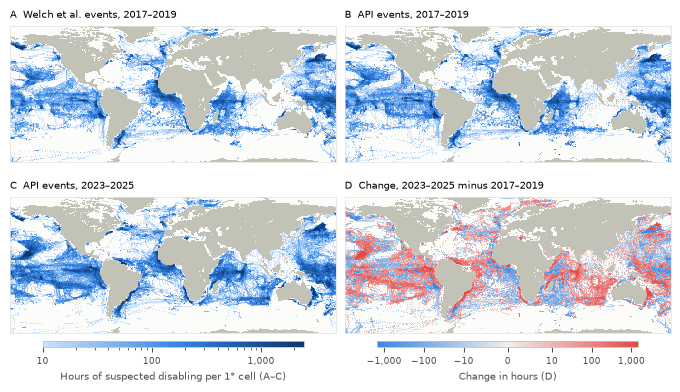

In [8]:
NAMES = {PAPER: "welch_events", P1: "2017_2019", P2: "2023_2025"}
H = {}
for label, g in GAPS.items():
    grid = gap_hours_raster(g[g["hours"] < 336].copy(), f"data/processed/gap_hours_{NAMES[label]}.tif")
    H[label] = grid.reshape(180, 4, 360, 4).sum(axis=(1, 3))  # 0.25 deg -> 1 deg

with rasterio.open("data/processed/sst_2017_2019.tif") as src:
    land = np.where(np.isnan(src.read(1)), 1.0, np.nan)


def draw(ax, data, cmap, norm, title, ylim=(-70, 80)):
    ext = [-180, 180, -90, 90]
    ax.set_facecolor(SURFACE)
    im = ax.imshow(np.ma.masked_equal(data, 0), extent=ext, cmap=cmap, norm=norm, interpolation="nearest")
    ax.imshow(land, extent=ext, cmap=ListedColormap([LAND]), interpolation="nearest")
    ax.set_ylim(*ylim)
    ax.set_xticks([])
    ax.set_yticks([])
    for s in ax.spines.values():
        s.set(visible=True, color=GRID, lw=0.5)
    ax.set_title(title, loc="left")
    return im


panels = [("Welch et al. events, 2017–2019" if k == PAPER else f"API events, {k}", H[k]) for k in (PAPER, P1, P2) if k in H]
seq_norm = LogNorm(vmin=10, vmax=np.percentile(np.concatenate([d[d > 0] for _, d in panels]), 99.5))
fig, axes = plt.subplots(2, 2, figsize=(W_FULL, 3.9), layout="constrained")
for ax, (title, data), letter in zip(axes.flat, panels, "ABC"):
    im = draw(ax, data, SEQ, seq_norm, f"{letter}  {title}")
for ax in list(axes.flat)[len(panels):3]:
    ax.set_visible(False)
plain = FuncFormatter(lambda v, _: f"{v:,.0f}".replace("-", "\u2212"))
fig.colorbar(im, ax=axes[:, 0], orientation="horizontal", shrink=0.8, aspect=40, pad=0.02, format=plain,
             label="Hours of suspected disabling per 1° cell (A–C)")
if P1 in H and P2 in H:
    diff = H[P2] - H[P1]
    lim = np.percentile(np.abs(diff[diff != 0]), 99)
    im = draw(axes[1, 1], diff, DIV, SymLogNorm(linthresh=10, vmin=-lim, vmax=lim), f"D  Change, {P2} minus {P1}")
    fig.colorbar(im, ax=axes[:, 1], orientation="horizontal", shrink=0.8, aspect=40, pad=0.02, format=plain,
                 label="Change in hours (D)")
else:
    axes[1, 1].set_visible(False)
save(fig, "fig_hotspots")

## Partial dependence (paper Fig. 4)

For each model, the upper figures show the most important drivers of 2017–2019 and the lower figures the most important drivers of 2023–2025, each with the curves of both periods

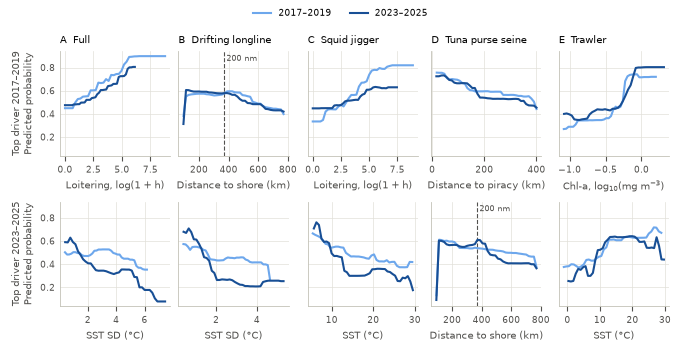

In [9]:
def partial_dependence(run, model, feature, n=40, n_rows=5000):
    m = xgb.XGBClassifier()
    m.load_model(f"{runs[run]}/model_{model}.json")
    X = pd.read_csv(f"{runs[run]}/model_df_{model}.csv")[m.get_booster().feature_names]
    X = X.sample(min(n_rows, len(X)), random_state=0)
    grid = np.linspace(*np.percentile(X[feature], [0.5, 99.5]), n)
    return grid, [m.predict_proba(X.assign(**{feature: v}))[:, 1].mean() for v in grid]


XLABEL = {"loitering_hours": "Loitering, log(1 + h)", "dist2coast": "Distance to shore (km)", "dist_mpa": "Distance to MPA (km)",
          "dist_piracy": "Distance to piracy (km)", "sst": "SST (°C)", "sst_var": "SST SD (°C)",
          "chl": "Chl-a, log$_{10}$(mg m$^{-3}$)", "eke": "EKE (m$^2$ s$^{-2}$)"}
fig, axes = plt.subplots(2, len(MODELS), figsize=(W_FULL, 3.4), sharey=True, layout="constrained")
for j, (m, title) in enumerate(MODELS.items()):
    top1 = importance(P1, m).idxmax()  # most important driver in 2017-2019
    top2 = importance(P2, m).drop(top1).idxmax()  # in 2023-2025 (the next one if both periods share the top driver)
    for ax, feature in zip(axes[:, j], (top1, top2)):
        ax.grid(color=GRID, lw=0.5)
        ax.set_axisbelow(True)
        for r in (P1, P2):
            if r in runs and os.path.exists(f"{runs[r]}/model_{m}.json"):
                ax.plot(*partial_dependence(r, m, feature), color=COL[r], lw=1.5, label=r)
            else:
                print("missing:", r, m)
        ax.set_xlabel(XLABEL[feature])
        if feature == "dist2coast":  # 200 nm = 370.4 km, the outer boundary of most EEZs
            ax.axvline(370.4, color=INK2, lw=0.8, ls="--", zorder=1)
            ax.text(385, 0.97, "200 nm", transform=ax.get_xaxis_transform(), va="top", fontsize=6, color=INK2)
        ax.tick_params(axis="y", length=0)
    axes[0, j].set_title(f"{'ABCDE'[j]}  {title}", loc="left")
axes[0, 0].set_ylabel(f"Top driver {P1}\nPredicted probability")
axes[1, 0].set_ylabel(f"Top driver {P2}\nPredicted probability")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside upper center", ncol=2, frameon=False)
save(fig, "fig_partial_dependence")